In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Define o repositório

In [2]:
base = "drive/My Drive/Colab Notebooks"
repository = "refactoring-toy-example"

Leitura dos dados do modelo

In [3]:
import pandas as pd

path = f"{base}/metadata/{repository}/modelo.csv"
data = pd.read_csv(path)

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

In [5]:
X = data[data.columns[1:-1]] 
y = data[data.columns[-1]] 
X.shape,y.shape

((151, 76), (151,))

Normalização dos dados

In [6]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [7]:
X_train.shape, X_test.shape

((120, 76), (31, 76))

In [8]:
from sklearn import preprocessing
'''
parametros = {
    "learning_rate": [0.01,0.03,1],
    "max_depth": [5,7,10],
    "n_estimators": [10,50,100,200,500]
}
'''
parametros = {
    "learning_rate": [0.01, 0.03,1],
    "max_depth": [5,7,10],
    "n_estimators": [10,50,100,200,500]
}

Vetor de respostas

In [ ]:
#min cv=5
#cv = GridSearchCV(xgb.XGBRegressor(), parametros, cv=10, n_jobs=-1, verbose=True)
cv = GridSearchCV(xgb.XGBRegressor(), parametros, cv=10, n_jobs=2, verbose=True)
cv.fit(X,y)

Fitting 10 folds for each of 45 candidates, totalling 450 fits


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done 116 tasks      | elapsed:   11.3s
[Parallel(n_jobs=2)]: Done 382 tasks      | elapsed:   38.8s


[00:23:37] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.


[Parallel(n_jobs=2)]: Done 450 out of 450 | elapsed:   42.1s finished


GridSearchCV(cv=10, error_score=nan,
             estimator=XGBRegressor(base_score=0.5, booster='gbtree',
                                    colsample_bylevel=1, colsample_bynode=1,
                                    colsample_bytree=1, gamma=0,
                                    importance_type='gain', learning_rate=0.1,
                                    max_delta_step=0, max_depth=3,
                                    min_child_weight=1, missing=None,
                                    n_estimators=100, n_jobs=1, nthread=None,
                                    objective='reg:linear', random_state=0,
                                    reg_alpha=0, reg_lambda=1,
                                    scale_pos_weight=1, seed=None, silent=None,
                                    subsample=1, verbosity=1),
             iid='deprecated', n_jobs=2,
             param_grid={'learning_rate': [0.01, 0.03, 1],
                         'max_depth': [5, 7, 10],
                         

Obtém os melhores parâmetros e estimadores

In [ ]:
bestmodel = cv.best_estimator_
bestparams = cv.best_params_
bestparams

{'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 200}

In [ ]:
#X_test = min_max_scaler.transform(X_test)
result = bestmodel.predict(X_test)

Verifica o erro

In [ ]:
from sklearn.metrics import mean_squared_error
error = mean_squared_error(y_test,result)
print(f"Erro: {error}")
print(f"Erro percentual: {(error/abs(-4-4))*100}%")

In [ ]:
y_test[:20]

In [ ]:
result[:20]

array([-0.36184227, -0.07771999, -0.07771999, -0.07771999,  0.45546764,
       -0.07771999, -0.07771999, -0.07771999, -0.07771999, -0.04363483,
       -0.07771999, -0.07771999, -0.07771999, -0.07771999, -0.07771999,
       -0.07771999, -0.07771999, -0.07771999, -0.07771999, -1.3631128 ],
      dtype=float32)

Armazena os dados do modelo treinado

In [ ]:
bestmodel.save_model(f"{base}/metadata/{repository}/modelo_treinado.json")

Ou a partir do modelo treinado externamente

In [9]:
import pandas as pd
import xgboost as xgb

bestmodel = xgb.XGBRegressor()
bestmodel.load_model(f"{base}/metadata/{repository}/modelo_treinado.json")

[22:27:14] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.


In [10]:
result = bestmodel.predict(X_test)

In [11]:
from sklearn.metrics import mean_squared_error
error = mean_squared_error(y_test,result)
print(f"Erro absoluto: {error}")
print(f"Erro percentual: {(error/abs(-4-4))*100}%")

Erro absoluto: 0.5910713511629588
Erro percentual: 7.388391889536986%


Instalação da biblioteca Shap

In [12]:
!!pip install shap

['Collecting shap',
 '\x1b[?25l  Downloading https://files.pythonhosted.org/packages/d2/17/37ee6c79cafbd9bb7423b54e55ea90beec66aa7638664d607bcc28de0bae/shap-0.36.0.tar.gz (319kB)',
 '',
 '\x1b[K     |█                               | 10kB 19.2MB/s eta 0:00:01',
 '\x1b[K     |██                              | 20kB 1.9MB/s eta 0:00:01',
 '\x1b[K     |███                             | 30kB 2.2MB/s eta 0:00:01',
 '\x1b[K     |████                            | 40kB 2.6MB/s eta 0:00:01',
 '\x1b[K     |█████▏                          | 51kB 2.6MB/s eta 0:00:01',
 '\x1b[K     |██████▏                         | 61kB 2.9MB/s eta 0:00:01',
 '\x1b[K     |███████▏                        | 71kB 3.0MB/s eta 0:00:01',
 '\x1b[K     |████████▏                       | 81kB 3.1MB/s eta 0:00:01',
 '\x1b[K     |█████████▏                      | 92kB 3.0MB/s eta 0:00:01',
 '\x1b[K     |██████████▎                     | 102kB 3.1MB/s eta 0:00:01',
 '\x1b[K     |███████████▎                    | 112kB 3.1MB/s 

Inicialização da visualização JS

In [13]:
import shap

Criação do Explainer

In [14]:
explainer = shap.TreeExplainer(bestmodel)
shap_values = explainer.shap_values(X_train)

Geração do Gráfico de Força (Cada arquivo)

In [15]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[6,:], X_train.iloc[6,:])

Gráfico de Força do Dataset Inteiro

In [16]:
# visualize the training set predictions
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values, X_train)

Análise de Impacto das Modificações

In [17]:
modificacoes = bestmodel.get_booster().feature_names

Criar tabela de valores de cada modificação (vazia)

In [18]:
from statistics import mean
from functools import reduce

tabela = {}
for modificacao in modificacoes:
  tabela[modificacao] = []

posicao = 0
for linha in X_train.values:
  conjunto = shap_values[posicao]
  pesos = list(map(lambda x: abs(x), filter(lambda x: x != 0, conjunto)))
  soma_total = reduce((lambda x,y: x+y), pesos)
  percentuais = list(map(lambda x: x/soma_total, pesos))
  if len(percentuais) > 0:
    percentuais_avg = mean(percentuais)

  contador = 0
  for item in linha:
    if item != 0:
      valor = shap_values[posicao][contador]
      #if valor != 0:
      modificacao = modificacoes[contador]
      percentual = abs(valor)/soma_total
      tabela[modificacao].append({
        "percentual": percentual,
        "acima_media": percentual >= percentuais_avg
      })

    contador = contador + 1
    
  posicao = posicao + 1

In [19]:
#tabela

Calcular Impacto Médio de cada Padrão de Modificação

In [20]:
result = {}
for modificacao,impactos in tabela.items():
  if len(impactos) > 0:
    #print(f"{modificacao}: {impactos}")
    result[modificacao] = mean(list(map(lambda x: x["percentual"], impactos)))

In [21]:
#result

Impacto médio dos padrões de modificação com ocorrência >= 2

In [22]:
import matplotlib.pyplot as plt

def plot(data, quantidade=None):
  fig = plt.gcf()
  fig.set_size_inches(12, 6.6)

  #data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  #x = data.keys()
  #y = list(map(lambda x: abs(x), data.values()))

  data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  if quantidade:
    x = list(data.keys())[:quantidade]
    y = list(map(lambda x: abs(x), data.values()))[:quantidade]
  else:
    x = data.keys()
    y = list(map(lambda x: abs(x), data.values()))

  
  p = plt.bar(x, y, orientation='vertical')

  plt.title("Percentual Médio de Impacto dos Padrões de Modificação")
  plt.ylabel("Impacto Médio nos Arquivos de Ocorrência")
  plt.xlabel("Padrões de Modificação")
  plt.xticks(rotation=45)

  plt.show()

Lista de Padrões das Modificações

In [23]:
lista_padroes = ['#76', '#60', '#80', '#41', '#59', '#61', '#142', '#9', '#43', '#77', '#107', '#3', '#2', '#50', '#45', '#46', '#1', '#88']

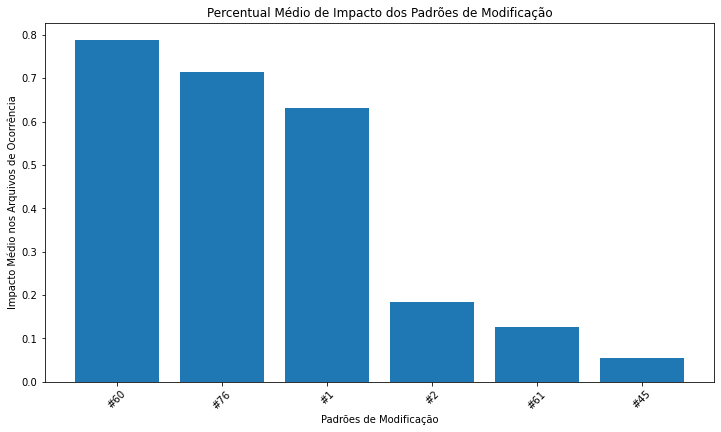

In [24]:
impacto_padroes = {}
for padrao in lista_padroes:
  if result[padrao] > 0:
    impacto_padroes[padrao] = result[padrao]

plot(impacto_padroes)

Frequência de Impacto acima da média das modificações do mesmo arquivo

In [25]:
ocorrencias = {}
for modificacao,items in tabela.items():
  size = len(items)
  contagem = 0
  if size > 0 and modificacao in lista_padroes:
    for item in items:
      if item["acima_media"]:
        contagem = contagem + 1
    ocorrencias[modificacao] = {
      "taxa": contagem/size,
      "tamanho": size
    }

In [26]:
#ocorrencias

In [27]:
ocorrencias_filtradas = {}
for modificacao,dados in ocorrencias.items():
  if dados['tamanho'] > 1 and dados['taxa'] > 0:
    ocorrencias_filtradas[modificacao] = dados['taxa']

In [28]:
import matplotlib.pyplot as plt

def plot_percentual(data, quantidade=None):
  fig = plt.gcf()
  fig.set_size_inches(12, 6.6)

  #data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  #x = data.keys()
  #y = list(map(lambda x: abs(x), data.values()))

  data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  if quantidade:
    x = list(data.keys())[:quantidade]
    y = list(map(lambda x: abs(x), data.values()))[:quantidade]
  else:
    x = data.keys()
    y = list(map(lambda x: abs(x), data.values()))

  
  p = plt.bar(x, y, orientation='vertical')

  plt.title("Frequência de Impacto Acima da Média dos Padrões de Modificação")
  plt.ylabel("Frequência da Impacto Superior a Média do Arquivo")
  plt.xlabel("Padrões de Modificação")
  plt.xticks(rotation=45)

  plt.show()

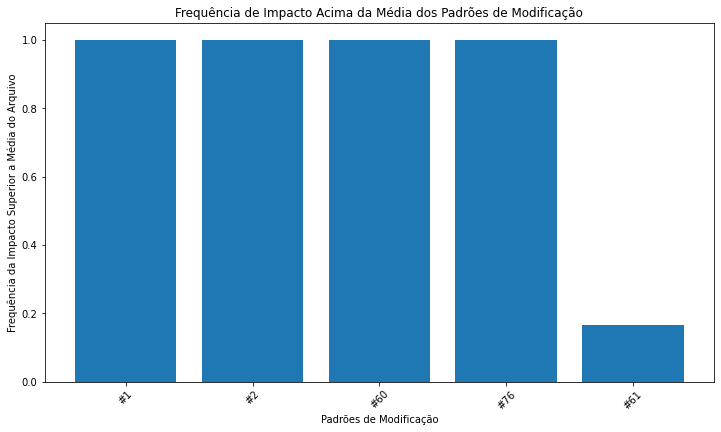

In [29]:
plot_percentual(ocorrencias_filtradas)

Verificando a predominância do tipo de modificação nos arquivos que ocorrem os principais padrões

In [30]:
#importantes = list(ocorrencias_filtradas.keys())
importantes = list(impacto_padroes.keys())
importantes

['#76', '#60', '#61', '#2', '#45', '#1']

Análise de ocorrência das principais modificações

In [31]:
ocorrencia_modificacoes_arquivo = []
i = 0
for linha in X_train.values:
  conjunto = {
    'resultado': y_train.values[i],
    'arquivos': {}
  }
  j = 0
  for item in linha:
    if item == 1 or item == -1:
      modificacao = modificacoes[j]
      conjunto["arquivos"][modificacao] = shap_values[i][j]
    j = j + 1
  ocorrencia_modificacoes_arquivo.append(conjunto)
  i = i + 1
  

In [32]:
arquivos_com_principais_modificacoes = []
for ocorrencia in ocorrencia_modificacoes_arquivo:
  for item in importantes:
    if item in ocorrencia['arquivos'].keys():
      arquivos_com_principais_modificacoes.append(ocorrencia)
      break

In [33]:
arquivos_percentuais = []
for item in arquivos_com_principais_modificacoes:
  soma = 0
  for num in list(item['arquivos'].values()):
    soma = soma + num
  if item['resultado'] != soma and soma != 0:
    proporcao = item['resultado']/soma
    #print(item['resultado'], soma, proporcao)
    novo = {
        'resultado': item['resultado'],
        'arquivos': {}
    }
    for arquivo,peso in item['arquivos'].items():
      #print(peso,proporcao)
      novo['arquivos'][arquivo] = peso*proporcao
    arquivos_percentuais.append(novo)

  else:
    arquivos_percentuais.append(item)


In [34]:
metricas_modificacoes = {}

In [35]:
for item in arquivos_percentuais:
  for modificacao,peso in item['arquivos'].items():
    if modificacao in metricas_modificacoes:
      metricas_modificacoes[modificacao].append(peso)
    else:
      metricas_modificacoes[modificacao] = [peso]

In [36]:
lista_avaliacoes = {}
for key,value in metricas_modificacoes.items():
  if key in importantes:
    lista_avaliacoes[key] = value

In [37]:
from google.colab import files

def plot_box(keys, values):
    fig, ax = plt.subplots()
    bp = ax.boxplot(
        values, 
        sym='k+'
    )

    ax.set_xlabel('Code pattern')
    ax.set_ylabel('Distribution of Maintainability Impact')
    plt.setp(bp['whiskers'], color='k', linestyle='-')
    plt.setp(bp['fliers'], markersize=3.0)
    #plt.title("Distribuição de Manutenabilidade por Padrão de Modificação")

    plt.xticks(np.arange(len(keys))+1, keys, rotation=55)
    fig.set_size_inches(15, 8)
    plt.savefig("boxplot-padroes.pdf",  bbox_inches='tight')
    files.download("boxplot-padroes.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

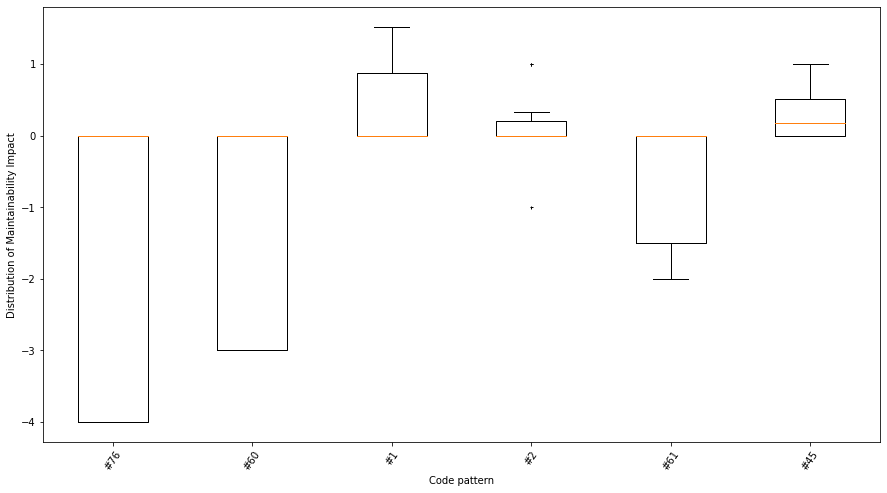

In [38]:
plot_box(lista_avaliacoes.keys(),lista_avaliacoes.values())

Matriz de correlação entre os principais padrões

In [39]:
!!pip install ppscore

['Collecting ppscore',
 '  Downloading https://files.pythonhosted.org/packages/90/df/b4ae18f31e2be37d81fa9956774bd192c0d3f759885f3b1974024bb37faa/ppscore-1.1.1.tar.gz',
 'Requirement already satisfied: pandas<2.0.0,>=1.0.0 in /usr/local/lib/python3.6/dist-packages (from ppscore) (1.1.3)',
 'Requirement already satisfied: scikit-learn<1.0.0,>=0.20.2 in /usr/local/lib/python3.6/dist-packages (from ppscore) (0.22.2.post1)',
 'Requirement already satisfied: numpy>=1.15.4 in /usr/local/lib/python3.6/dist-packages (from pandas<2.0.0,>=1.0.0->ppscore) (1.18.5)',
 'Requirement already satisfied: python-dateutil>=2.7.3 in /usr/local/lib/python3.6/dist-packages (from pandas<2.0.0,>=1.0.0->ppscore) (2.8.1)',
 'Requirement already satisfied: pytz>=2017.2 in /usr/local/lib/python3.6/dist-packages (from pandas<2.0.0,>=1.0.0->ppscore) (2018.9)',
 'Requirement already satisfied: scipy>=0.17.0 in /usr/local/lib/python3.6/dist-packages (from scikit-learn<1.0.0,>=0.20.2->ppscore) (1.4.1)',
 'Requirement 

In [40]:
import ppscore as pps

Correlação entre duas modificações

In [41]:
nova_tabela = pd.DataFrame(data=shap_values, columns=modificacoes)
#nova_tabela = pd.DataFrame(data=shap_values)

In [42]:
#nova_tabela

In [43]:
colunas = list(lista_avaliacoes.keys())

In [44]:
tabela_filtrada = nova_tabela[colunas]

In [45]:
#pps.matrix(tabela_filtrada)

In [46]:
  !!pip install seaborn

['Requirement already satisfied: seaborn in /usr/local/lib/python3.6/dist-packages (0.11.0)',
 'Requirement already satisfied: scipy>=1.0 in /usr/local/lib/python3.6/dist-packages (from seaborn) (1.4.1)',
 'Requirement already satisfied: matplotlib>=2.2 in /usr/local/lib/python3.6/dist-packages (from seaborn) (3.2.2)',
 'Requirement already satisfied: numpy>=1.15 in /usr/local/lib/python3.6/dist-packages (from seaborn) (1.18.5)',
 'Requirement already satisfied: pandas>=0.23 in /usr/local/lib/python3.6/dist-packages (from seaborn) (1.1.3)',
 'Requirement already satisfied: kiwisolver>=1.0.1 in /usr/local/lib/python3.6/dist-packages (from matplotlib>=2.2->seaborn) (1.2.0)',
 'Requirement already satisfied: python-dateutil>=2.1 in /usr/local/lib/python3.6/dist-packages (from matplotlib>=2.2->seaborn) (2.8.1)',
 'Requirement already satisfied: pyparsing!=2.0.4,!=2.1.2,!=2.1.6,>=2.0.1 in /usr/local/lib/python3.6/dist-packages (from matplotlib>=2.2->seaborn) (2.4.7)',
 'Requirement already 

In [47]:
import seaborn as sns

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

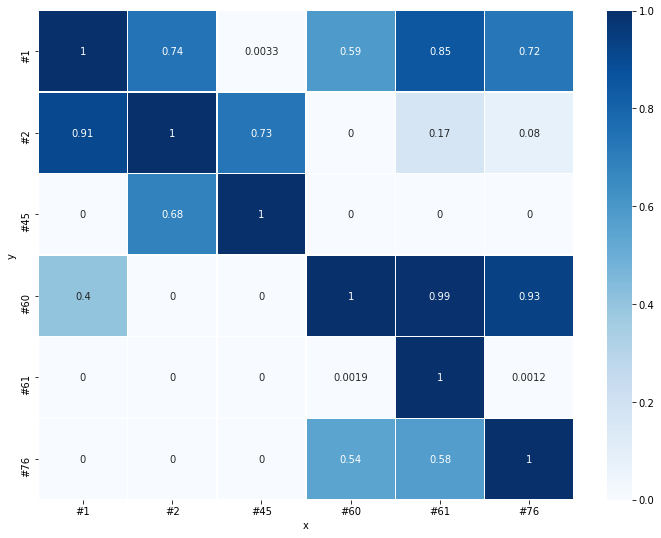

In [48]:
import matplotlib.pyplot as plt

matrix_df = pps.matrix(tabela_filtrada)[['x', 'y', 'ppscore']].pivot(columns='x', index='y', values='ppscore')
plt.figure(figsize = (12,9))

sns.heatmap(matrix_df, vmin=0, vmax=1, cmap="Blues", linewidths=0.5, annot=True)
plt.savefig("matriz.pdf",  bbox_inches='tight')
files.download("matriz.pdf")


Verificação dos tipos de modificação que ocorrem juntamente com as principais modificações

In [49]:
principais_modificacoes = ['#1','#2','#60','#61','#76','#45']

In [50]:
resumo = {}

for modificacao in principais_modificacoes:
  resumo[modificacao] = []

i = 0
for linha in X_train.values:
  j = 0
  modificacoes_linha = []
  for item in linha:
    if item != 0:
      modificacao = modificacoes[j]
      modificacoes_linha.append(modificacao)
    j = j + 1
  
  if len(modificacoes_linha) > 0:
    for principal in principais_modificacoes:
      if principal in modificacoes_linha:
        resumo[principal].append(modificacoes_linha)
  
  i = i + 1

Função de leitura de arquivo ZIP

In [ ]:
#ler arquivo zip
import zipfile
import json

#multipattern_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/multipattern.zip", "r")
def read_file_from_zip(zipfile, file):
  data = zipfile.read(file)
  return json.loads(data.decode("utf-8"))

In [ ]:
clusters_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/clusters.zip","r")
#read_file_from_zip(clusters_zip, f"clusters/#3.json")

In [ ]:
dados = {}
temporario = {}
for modificacao, listas in resumo.items():
  dados[modificacao] = []

  for lista in listas:
    conjunto = []
    for numero in lista:
      #if numero != modificacao:
      if numero in temporario:
        tipo = temporario[numero]
      else:
        arquivo = read_file_from_zip(clusters_zip, f"clusters/{numero}.json")
        tipos = []
        for elemento in arquivo['base']['items']:
          tipos.append(elemento['type'])
        if "update" in tipos:
          tipo = "update"
        elif "move" in tipos:
          tipo = "move"
        elif "insert" in tipos:
          tipo = "insert"
        else:
          tipo = "delete"

      conjunto.append(tipo)
    dados[modificacao].append(conjunto)


In [ ]:
resultado = {}
for modificacao, listagem in dados.items():
  elemento = {
      "arquivos": len(listagem),
      "modificacoes_por_arquivo": [],
      "tipos": {
          "insert": 0,
          "delete": 0,
          "move": 0,
          "update": 0
      }
  }

  for lista in listagem:
    elemento["modificacoes_por_arquivo"].append(len(lista))
    for item in lista:
      elemento["tipos"][item] = elemento["tipos"][item] + 1

  elemento["media"] = 0;
  for item in elemento["modificacoes_por_arquivo"]:
    elemento["media"] = elemento["media"] + item;
  elemento["media"] = elemento["media"]/elemento["arquivos"];
  
  resultado[modificacao] = elemento



In [ ]:
resultado

{'#1': {'arquivos': 7,
  'media': 5.0,
  'modificacoes_por_arquivo': [3, 6, 6, 6, 6, 5, 3],
  'tipos': {'delete': 2, 'insert': 4, 'move': 29, 'update': 0}},
 '#2': {'arquivos': 13,
  'media': 4.076923076923077,
  'modificacoes_por_arquivo': [3, 3, 3, 6, 6, 3, 6, 6, 5, 3, 3, 3, 3],
  'tipos': {'delete': 2, 'insert': 4, 'move': 47, 'update': 0}},
 '#45': {'arquivos': 4,
  'media': 2.5,
  'modificacoes_por_arquivo': [2, 3, 3, 2],
  'tipos': {'delete': 2, 'insert': 0, 'move': 8, 'update': 0}},
 '#60': {'arquivos': 9,
  'media': 1.2222222222222223,
  'modificacoes_por_arquivo': [1, 1, 1, 1, 1, 1, 3, 1, 1],
  'tipos': {'delete': 1, 'insert': 1, 'move': 9, 'update': 0}},
 '#61': {'arquivos': 6,
  'media': 1.0,
  'modificacoes_por_arquivo': [1, 1, 1, 1, 1, 1],
  'tipos': {'delete': 0, 'insert': 0, 'move': 0, 'update': 6}},
 '#76': {'arquivos': 5,
  'media': 2.2,
  'modificacoes_por_arquivo': [1, 7, 1, 1, 1],
  'tipos': {'delete': 6, 'insert': 0, 'move': 0, 'update': 5}}}

Média de modificações nos arquivos que contém as ocorrências dos padrões

In [ ]:
total = 0
items = list(resultado.values())
for item in items:
  total = total + item["media"]

print(f"Média: {total/len(items)}")

Média: 2.6665242165242162


Relação de mapeamentos de inserção/deleção por update/move

In [ ]:
total = 0
print(list(resultado.keys()))
items = list(resultado.values())
for item in items:
  tipo = item["tipos"]
  valor = ((tipo["insert"]+tipo["delete"])/(tipo["update"]+tipo["move"]))
  print(valor)
  total = total + valor


['#1', '#2', '#60', '#61', '#76', '#45']
0.20689655172413793
0.1276595744680851
0.2222222222222222
0.0
1.2
0.25


In [ ]:
print(f"Média: {total/len(items)}")

Média: 0.3344630580690742
